In [3]:
import os
import geopandas as gpd
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_recall_curve,
    classification_report
)
import shap
import matplotlib.pyplot as plt

In [4]:
# ==============================================================================
# 1. LOAD GTFS-ENRICHED DATASET & ENSURE GEOMETRY FEATURES EXIST
# ==============================================================================
gtfs_file = os.path.join("..", "Datasets", "RZLT_Samples", "RZLT_AllCodes_10to1_WithGTFS.geojson")
if not os.path.exists(gtfs_file):
    gtfs_file = "RZLT_AllCodes_10to1_WithGTFS.geojson"

gdf = gpd.read_file(gtfs_file)
if gdf.crs != "EPSG:2157":
    gdf = gdf.to_crs(epsg=2157)

area_m2 = gdf.geometry.area
perim_m = gdf.geometry.length
gdf['SHAPE_COMPACTNESS'] = (4 * np.pi * area_m2) / np.maximum(perim_m ** 2, 1e-6)
gdf['PERIM_TO_AREA'] = perim_m / np.maximum(area_m2, 1e-6)
gdf['LOG_SITE_AREA'] = np.log1p(gdf['SITE_AREA'])

coords = np.column_stack([gdf['centroid_x'], gdf['centroid_y']])
parcel_tree = cKDTree(coords)
gdf['PARCELS_WITHIN_500M'] = [len(idx) - 1 for idx in parcel_tree.query_ball_point(coords, r=500.0)]

In [5]:
# ==============================================================================
# 2. DEFINE POLICY-ONLY FEATURE SET (EXCLUDING LOCAL_AUTHORITY)
# ==============================================================================
num_cols = [
    'SITE_AREA', 'LOG_SITE_AREA',
    'SHAPE_COMPACTNESS', 'PERIM_TO_AREA', 'PARCELS_WITHIN_500M',
    'DIST_TO_BUS_M', 'DIST_TO_RAIL_LUAS_M', 'DIST_TO_ANY_TRANSIT_M',
    'BUS_STOPS_WITHIN_500M', 'LOG_DIST_BUS', 'LOG_DIST_RAIL_LUAS'
]
num_cols = [c for c in num_cols if c in gdf.columns]
cat_cols = ['ZONE_GZT']  # LOCAL_AUTHORITY intentionally omitted

gdf['ZONE_GZT'] = gdf['ZONE_GZT'].fillna("Unknown").astype(str).str.strip()

X_df = gdf[num_cols + cat_cols].copy()
y = gdf['target'].values  # 1 = Included (1,2,5,6), 0 = Excluded (3,4)

In [6]:
# ==============================================================================
# 3. 5-FOLD STRATIFIED CROSS-VALIDATION (POLICY-ONLY MODEL)
# ==============================================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = np.zeros(len(y))
fold_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_df, y), start=1):
    X_tr_raw, X_va_raw = X_df.iloc[train_idx], X_df.iloc[val_idx]
    y_tr, y_va = y[train_idx], y[val_idx]

    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    tr_cat = ohe.fit_transform(X_tr_raw[cat_cols])
    va_cat = ohe.transform(X_va_raw[cat_cols])

    X_tr = np.hstack([X_tr_raw[num_cols].values, tr_cat])
    X_va = np.hstack([X_va_raw[num_cols].values, va_cat])

    fold_spw = (y_tr == 0).sum() / (y_tr == 1).sum()

    model = XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.85,
        colsample_bytree=0.85,
        scale_pos_weight=fold_spw,
        eval_metric='aucpr',
        random_state=42 + fold,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)

    probs = model.predict_proba(X_va)[:, 1]
    oof_probs[val_idx] = probs

    fold_scores.append({
        'Fold': fold,
        'ROC_AUC': roc_auc_score(y_va, probs),
        'PR_AUC_Inclusion(1)': average_precision_score(y_va, probs),
        'PR_AUC_Exclusion(0)': average_precision_score(1 - y_va, 1 - probs)
    })

scores_df = pd.DataFrame(fold_scores)
print("=== Policy-Only 5-Fold CV Results (No LOCAL_AUTHORITY) ===")
print(scores_df.to_string(index=False))
print("\nMean Performance:")
print(scores_df[['ROC_AUC', 'PR_AUC_Inclusion(1)', 'PR_AUC_Exclusion(0)']].mean().round(4)) 

=== Policy-Only 5-Fold CV Results (No LOCAL_AUTHORITY) ===
 Fold  ROC_AUC  PR_AUC_Inclusion(1)  PR_AUC_Exclusion(0)
    1 0.955808             0.995233             0.734538
    2 0.960947             0.996039             0.709538
    3 0.955263             0.995276             0.758515
    4 0.939467             0.991411             0.739177
    5 0.961069             0.996162             0.748318

Mean Performance:
ROC_AUC                0.9545
PR_AUC_Inclusion(1)    0.9948
PR_AUC_Exclusion(0)    0.7380
dtype: float64


In [7]:
# ==============================================================================
# 4. THRESHOLD OPTIMIZATION FOR MINORITY EXCLUSION CLASS (CLASS 0)
# ==============================================================================
# Find probability cutoff maximizing F1 on Excluded (Class 0)
prec_0, rec_0, thresholds = precision_recall_curve(1 - y, 1 - oof_probs)
f1_0 = (2 * prec_0 * rec_0) / np.maximum(prec_0 + rec_0, 1e-8)
best_idx = np.argmax(f1_0[:-1])
best_excl_prob_cutoff = thresholds[best_idx]
best_incl_threshold = 1.0 - best_excl_prob_cutoff

oof_preds_opt = (oof_probs >= best_incl_threshold).astype(int)
print(f"\nOptimal Inclusion Probability Threshold: {best_incl_threshold:.4f} (Max Exclusion F1: {f1_0[best_idx]:.4f})")
print("=== Out-of-Fold Classification Report (Threshold-Tuned) ===")
print(classification_report(y, oof_preds_opt, target_names=['Excluded (3,4)', 'Included (1,2,5,6)']))


Optimal Inclusion Probability Threshold: 0.2763 (Max Exclusion F1: 0.7065)
=== Out-of-Fold Classification Report (Threshold-Tuned) ===
                    precision    recall  f1-score   support

    Excluded (3,4)       0.71      0.70      0.71       537
Included (1,2,5,6)       0.97      0.97      0.97      5766

          accuracy                           0.95      6303
         macro avg       0.84      0.84      0.84      6303
      weighted avg       0.95      0.95      0.95      6303



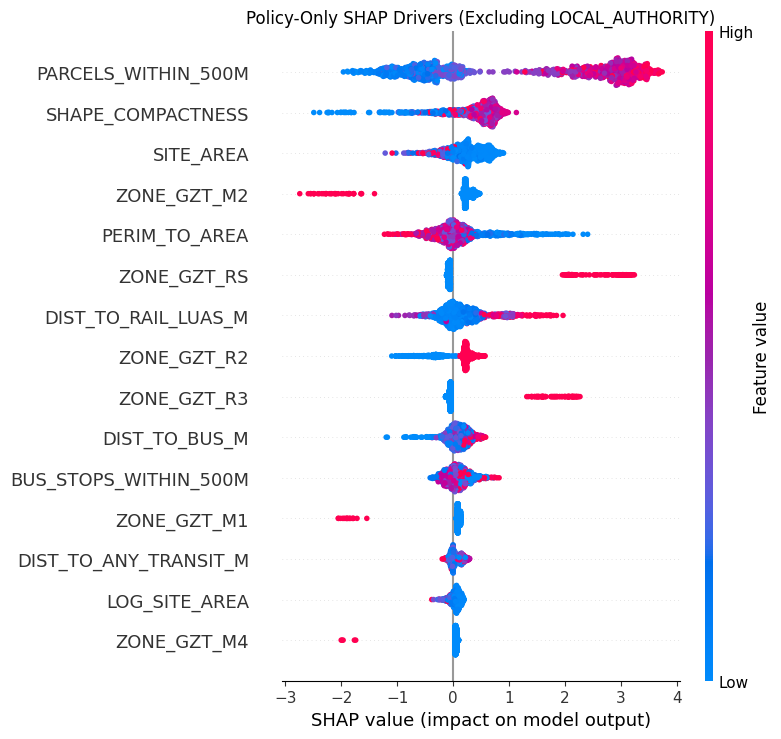

In [8]:
# ==============================================================================
# 5. SHAP BEESWARM PLOT (PHYSICAL, ZONING & TRANSIT DRIVERS ONLY)
# ==============================================================================
feature_names = num_cols + list(ohe.get_feature_names_out(cat_cols))
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_va)
shap_values.feature_names = feature_names

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_va, feature_names=feature_names, max_display=15, show=False)
plt.title("Policy-Only SHAP Drivers (Excluding LOCAL_AUTHORITY)", fontsize=12)
plt.tight_layout()
plt.show()